# Training

## Inputs:
- The model architecture is defined in [models.py](model.py)
- All training data is contained in [data/flux_tensor.pt](data/flux_tensor.pt) which was generated using ..

## Outputs: 
- Save models to [trained_models](trained_models).

In [1]:
import pandas as pd
import numpy as np
import xarray as xr
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import os

from models import FluxNet
from models import compute_divergence_field

from configs import N_ensemble

device = "cuda" if torch.cuda.is_available() else "cpu"

## 1. Load data

In [2]:
data = torch.load("data/flux_tensor.pt", weights_only = False)
print("Shape of training data:", data.shape)

### Make torch.dataset ###
# takes two separate tensors as input so split into model input (x, y) and output (XV, YV)
dataset = TensorDataset(data[:, :2], data[:, 2:])

# Inspect
# Shape of (first) X sample
print(dataset[0][0].shape)
# Shape of (first) Y sample
print(dataset[0][1].shape)

### Create DataLoader ###
all_loader = DataLoader(dataset, batch_size = 1024, shuffle = True)

Shape of training data: torch.Size([237475, 4])
torch.Size([2])
torch.Size([2])


## 2. Train one model (run 0)

In [3]:
model = FluxNet().to(device)

# 5e-3 was a bit jittery
optim = torch.optim.AdamW(model.parameters(), lr = 1e-3, weight_decay = 1e-7)
loss_function = nn.MSELoss()

# NOTE: Hardcode for now
epochs = 24
# epochs = 10

losses = []

for ep in range(1, epochs + 1):
    # ------------------ TRAIN ------------------
    model.train()
    train_loss_sum = 0.0
    
    # NOTE: Train on ALL data (no split)
    for i, (X_batch, Y_batch) in enumerate(all_loader):

        X_batch = X_batch.to(device)
        Y_batch = Y_batch.to(device)

        optim.zero_grad(set_to_none = True)

        Y_hat = model(X_batch)

        loss = loss_function(Y_hat, Y_batch)
        
        loss.backward()
        optim.step()

        train_loss_sum += loss.item() * X_batch.size(0)

    epoch_avg_train_loss = train_loss_sum / len(all_loader.dataset)

    # store for plotting later
    losses.append(epoch_avg_train_loss)

    # Print every epoch: ~ 2 min per epoch
    # ~14 min for 10 epochs on GPU
    print(f"[epoch {ep:03d}] train_loss = {epoch_avg_train_loss:.6f}")

# ------------------ SAVE ------------------
# Save model and losses for run 0
torch.save(model.state_dict(), "trained_models/fluxnet_run_0_trained_model.pth")
pd.DataFrame({'train_loss': losses}).to_csv("trained_models/fluxnet_run_0_losses_over_epochs.csv", index = False)

[epoch 001] train_loss = 0.063890
[epoch 002] train_loss = 0.004306
[epoch 003] train_loss = 0.003388
[epoch 004] train_loss = 0.002931
[epoch 005] train_loss = 0.002860
[epoch 006] train_loss = 0.002658
[epoch 007] train_loss = 0.002389
[epoch 008] train_loss = 0.002288
[epoch 009] train_loss = 0.002176
[epoch 010] train_loss = 0.002164
[epoch 011] train_loss = 0.001971
[epoch 012] train_loss = 0.001869
[epoch 013] train_loss = 0.001748
[epoch 014] train_loss = 0.001717
[epoch 015] train_loss = 0.001661
[epoch 016] train_loss = 0.001621
[epoch 017] train_loss = 0.001625
[epoch 018] train_loss = 0.001554
[epoch 019] train_loss = 0.001535
[epoch 020] train_loss = 0.001507
[epoch 021] train_loss = 0.001518
[epoch 022] train_loss = 0.001443
[epoch 023] train_loss = 0.001436
[epoch 024] train_loss = 0.001432


Observation: at 24 epochs it is still converging.

### Visualise loss convergence

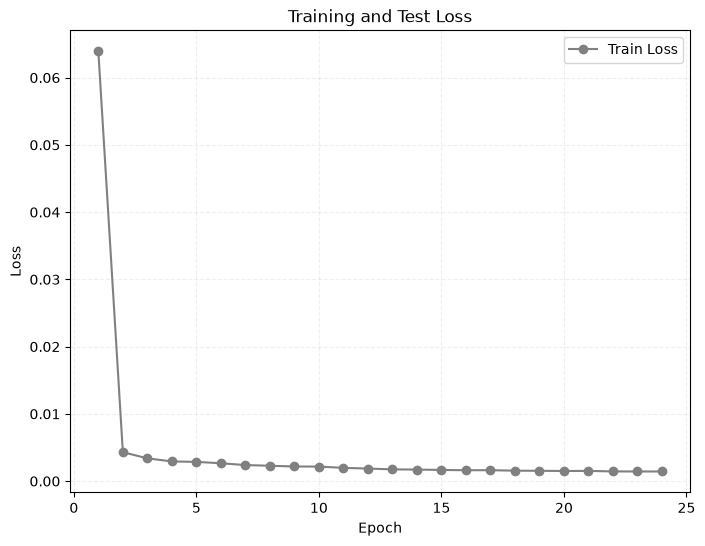

In [4]:
# We still have `losses` from run 0 in memory from above
epochs = range(1, len(losses) + 1)

plt.figure(figsize = (8, 6))
plt.plot(epochs, losses, label = "Train Loss", marker = "o", color = "gray")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Test Loss")

plt.legend()

plt.grid(True, linestyle = "--", alpha = 0.2)
# plt.ylim(0, 0.3)
plt.show()

## 3. Train remaining ensemble members

Consider changing more hyperparameters in the training for more diversity.

In [5]:
# Training the remaining N_ensemble - 1 ensemble members
# In N_ensemble = 5, this part trains 4 more ensemble members (run 1, run 2, run 3, run 4)
for (e) in range(1, N_ensemble):
    print(f"Training ensemble member {e}")

    model = FluxNet().to(device)

    # 5e-3 was a bit jittery
    optim = torch.optim.AdamW(model.parameters(), lr = 1e-3, weight_decay = 1e-7)
    loss_function = nn.MSELoss()

    # NOTE: Hardcode for now
    epochs = 24
    # epochs = 10

    losses = []

    for ep in range(1, epochs + 1):
        # ------------------ TRAIN ------------------
        model.train()
        train_loss_sum = 0.0
        
        # NOTE: Train on ALL data (no split)
        for i, (X_batch, Y_batch) in enumerate(all_loader):

            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            optim.zero_grad(set_to_none = True)

            Y_hat = model(X_batch)

            loss = loss_function(Y_hat, Y_batch)
            
            loss.backward()
            optim.step()

            train_loss_sum += loss.item() * X_batch.size(0)

        epoch_avg_train_loss = train_loss_sum / len(all_loader.dataset)

        # store for plotting later
        losses.append(epoch_avg_train_loss)

        # Print every epoch: ~ 2 min per epoch
        # ~14 min for 10 epochs on GPU
        print(f"[epoch {ep:03d}] train_loss = {epoch_avg_train_loss:.6f}")

    # ------------------ SAVE ------------------
    # Save model and losses for run 0
    torch.save(model.state_dict(), f"trained_models/fluxnet_run_{e}_trained_model.pth")
    pd.DataFrame({'train_loss': losses}).to_csv(f"trained_models/fluxnet_run_{e}_losses_over_epochs.csv", index = False)

Training ensemble member 1
[epoch 001] train_loss = 0.053603
[epoch 002] train_loss = 0.004284
[epoch 003] train_loss = 0.003596
[epoch 004] train_loss = 0.003653
[epoch 005] train_loss = 0.003553
[epoch 006] train_loss = 0.003476
[epoch 007] train_loss = 0.003410
[epoch 008] train_loss = 0.003271
[epoch 009] train_loss = 0.002962
[epoch 010] train_loss = 0.002530
[epoch 011] train_loss = 0.002059
[epoch 012] train_loss = 0.001934
[epoch 013] train_loss = 0.001751
[epoch 014] train_loss = 0.001682
[epoch 015] train_loss = 0.001612
[epoch 016] train_loss = 0.001613
[epoch 017] train_loss = 0.001588
[epoch 018] train_loss = 0.001516
[epoch 019] train_loss = 0.001607
[epoch 020] train_loss = 0.001526
[epoch 021] train_loss = 0.001543
[epoch 022] train_loss = 0.001493
[epoch 023] train_loss = 0.001468
[epoch 024] train_loss = 0.001486
Training ensemble member 2
[epoch 001] train_loss = 0.045922
[epoch 002] train_loss = 0.004083
[epoch 003] train_loss = 0.003627
[epoch 004] train_loss = 0.0